# 05 · Sellers & Geography

**Questions:** How concentrated is revenue among sellers? Which sellers need action? Where in Brazil is delivery
failing, and why?

Data: `analysis.seller_scorecard`, `analysis.state_delivery`, `marts.fact_orders`, `marts.dim_seller`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ecom import viz
from ecom.db import query, table

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

## 1. Seller concentration

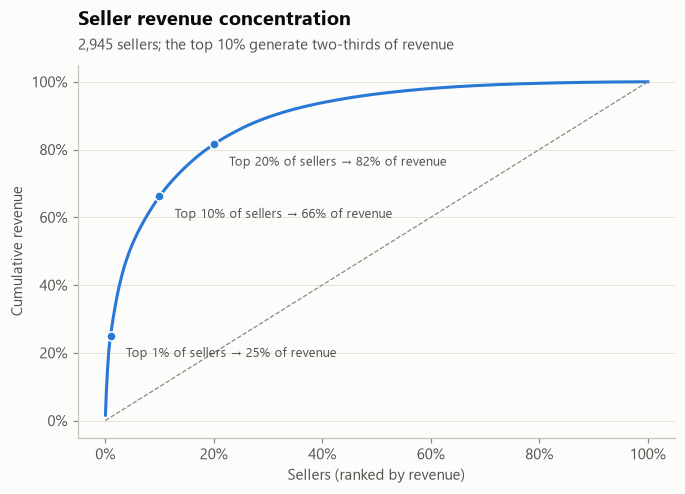

In [ ]:
sc = (
    table("analysis.seller_scorecard")
    .dropna(subset=["revenue"])
    .sort_values("revenue", ascending=False)
)
cum_rev = sc["revenue"].cumsum() / sc["revenue"].sum() * 100
cum_sellers = np.arange(1, len(sc) + 1) / len(sc) * 100

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(cum_sellers, cum_rev, color=viz.BLUE)
ax.plot([0, 100], [0, 100], color=viz.MUTED, linewidth=0.8, linestyle="--")
for pct in (1, 10, 20):
    idx = int(len(sc) * pct / 100) - 1
    ax.scatter(
        cum_sellers[idx], cum_rev.iloc[idx], color=viz.BLUE, s=36, zorder=3, edgecolor=viz.SURFACE
    )
    ax.annotate(
        f"Top {pct}% of sellers → {cum_rev.iloc[idx]:.0f}% of revenue",
        (cum_sellers[idx], cum_rev.iloc[idx]),
        xytext=(10, -14),
        textcoords="offset points",
        fontsize=8.5,
        color=viz.INK_2,
    )
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Sellers (ranked by revenue)")
ax.set_ylabel("Cumulative revenue")
ax.set_title("Seller revenue concentration")
viz.subtitle(ax, f"{len(sc):,} sellers; the top 10% generate two-thirds of revenue")
viz.save(fig, "seller_concentration")
plt.show()

## 2. Which sellers need action?
Sellers with ≥ 30 orders, placed by volume (revenue) and quality (negative-review rate), split at the medians.

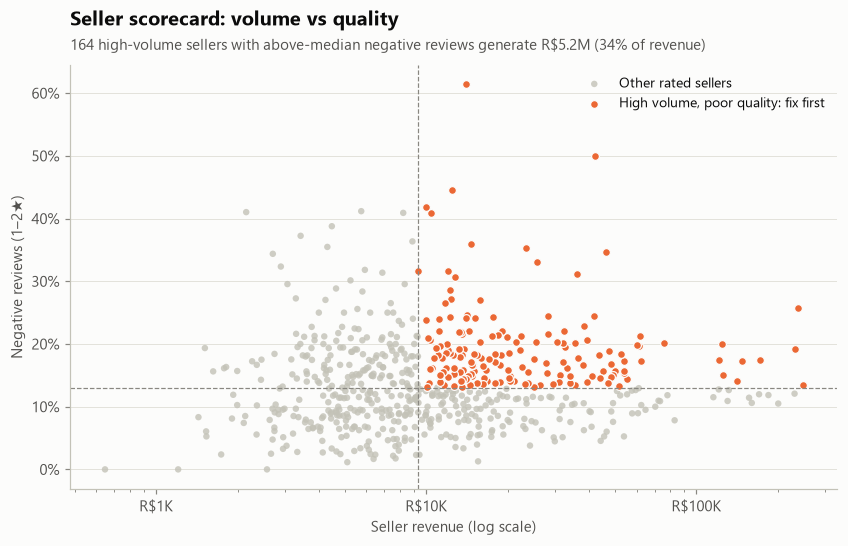

,sellers,revenue,late_pct,negative_review_pct,revenue_share_pct
action_quadrant,,,,,
"High volume, poor quality: fix first",164,"5,205,562.21",8.43,19.41,33.86
Star: protect,153,"5,036,831.96",4.61,9.24,32.77
Low volume,2312,"3,390,588.18",7.13,15.08,22.06
"Quality, low volume: grow",164,"886,316.89",4.51,7.88,5.77
"Low volume, poor quality: review",152,"852,441.85",8.70,19.70,5.55


In [ ]:
rated = sc.query("action_quadrant != 'Low volume'").copy()
fix = rated["action_quadrant"].str.startswith("High volume, poor")

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    rated.loc[~fix, "revenue"],
    rated.loc[~fix, "negative_review_pct"],
    s=18,
    color=viz.NEUTRAL,
    alpha=0.8,
    label="Other rated sellers",
    edgecolor="none",
)
ax.scatter(
    rated.loc[fix, "revenue"],
    rated.loc[fix, "negative_review_pct"],
    s=26,
    color=viz.ORANGE,
    label="High volume, poor quality: fix first",
    edgecolor=viz.SURFACE,
    linewidth=0.8,
)
ax.axvline(rated["revenue"].median(), color=viz.MUTED, linewidth=0.8, linestyle="--")
ax.axhline(rated["negative_review_pct"].median(), color=viz.MUTED, linewidth=0.8, linestyle="--")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(viz.BRL)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Seller revenue (log scale)")
ax.set_ylabel("Negative reviews (1–2★)")
ax.legend(loc="upper right")
ax.set_title("Seller scorecard: volume vs quality")
viz.subtitle(
    ax,
    "164 high-volume sellers with above-median negative reviews generate R$5.2M (34% of revenue)",
)
viz.save(fig, "seller_quadrants")
plt.show()

(
    sc.groupby("action_quadrant")
    .agg(
        sellers=("seller_id", "size"),
        revenue=("revenue", "sum"),
        late_pct=("late_pct", "mean"),
        negative_review_pct=("negative_review_pct", "mean"),
    )
    .assign(revenue_share_pct=lambda x: 100 * x["revenue"] / x["revenue"].sum())
    .sort_values("revenue", ascending=False)
)

In [ ]:
# The sellers to call first: biggest revenue in the 'fix first' quadrant
sc.query("action_quadrant.str.startswith('High volume, poor')").head(10)[
    [
        "seller_id",
        "seller_state",
        "orders",
        "revenue",
        "late_pct",
        "avg_review",
        "negative_review_pct",
    ]
]

,seller_id,seller_state,orders,revenue,late_pct,avg_review,negative_review_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1132,"247,007.06",10.50,4.13,13.52
1,7c67e1448b00f6e969d365cea6b010ab,SP,982,"237,806.69",9.15,3.49,25.72
2,4a3ca9315b744ce9f8e9374361493884,SP,1806,"231,220.43",9.71,3.83,19.16
6,1025f0e2d44d7041d6cf58b6550e0bfa,SP,915,"171,924.96",7.91,3.99,17.42
10,6560211a19b47992c3666cc44a7e94c0,SP,1854,"148,050.94",5.28,3.93,17.36
11,1f50f920176fa81dab994f9023523100,SP,1404,"141,712.94",8.86,4.13,14.15
14,cc419e0650a3c5ba77189a1882b7556a,SP,1706,"125,936.99",5.27,4.07,15.08
15,5dceca129747e92ff8ef7a997dc4f8ca,SP,325,"124,702.92",5.59,3.98,19.94
17,7d13fca15225358621be4086e1eb0964,SP,565,"120,934.47",11.47,4.02,17.47
21,cca3071e3e9bb7d12640c9fbe2301306,SP,704,"76,033.68",4.92,3.85,20.09


The "fix first" sellers have nearly **twice the late rate** of the "Star" sellers (8.4% vs 4.6%). Given notebook 04, that
alone explains much of their poor ratings. This is an operations problem (dispatch speed, carrier choice), not a product problem.

## 3. Geography: where delivery fails

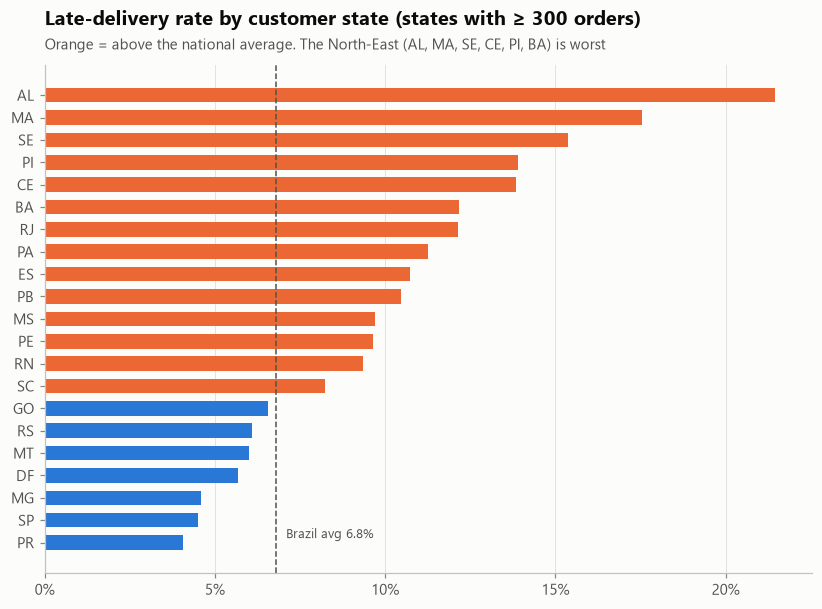

,state,delivered_orders,avg_delivery_days,median_delivery_days,avg_promised_days,late_pct,avg_freight,freight_share_pct,avg_distance_km,avg_review
0,AL,396,24.50,22.30,32.50,21.46,38.61,16.25,"1,832.00",3.85
1,MA,713,21.50,19.20,30.30,17.53,42.78,20.78,"2,104.00",3.83
2,SE,332,21.40,17.90,30.60,15.36,41.13,19.52,"1,653.00",3.90
3,PI,475,19.40,16.30,30.00,13.89,42.99,19.46,"1,957.00",3.99
4,CE,1273,21.20,18.20,31.20,13.83,36.48,17.56,"2,187.00",3.94
6,BA,3253,19.30,16.90,29.40,12.17,29.97,16.50,"1,346.00",3.93
7,RJ,12310,15.30,12.00,26.30,12.14,23.96,14.41,490.00,3.97
8,PA,942,23.80,21.10,37.00,11.25,39.66,17.73,"2,283.00",3.91


In [ ]:
st = table("analysis.state_delivery").query("delivered_orders >= 300").sort_values("late_pct")
national = query(
    "SELECT 100 * avg(is_late::INT) AS v FROM marts.fact_orders WHERE is_delivered AND in_analysis_window"
)["v"][0]
above = st["late_pct"] > national

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(st["state"], st["late_pct"], color=np.where(above, viz.ORANGE, viz.BLUE), height=0.65)
ax.axvline(national, color=viz.INK_2, linewidth=1, linestyle="--")
ax.text(national + 0.3, 0.2, f"Brazil avg {national:.1f}%", fontsize=8.5, color=viz.INK_2)
ax.xaxis.set_major_formatter(viz.PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Late-delivery rate by customer state (states with ≥ 300 orders)")
viz.subtitle(
    ax, "Orange = above the national average. The North-East (AL, MA, SE, CE, PI, BA) is worst"
)
viz.save(fig, "state_late_rate")
plt.show()

st.sort_values("late_pct", ascending=False).head(8)

## 4. Why: distance from sellers

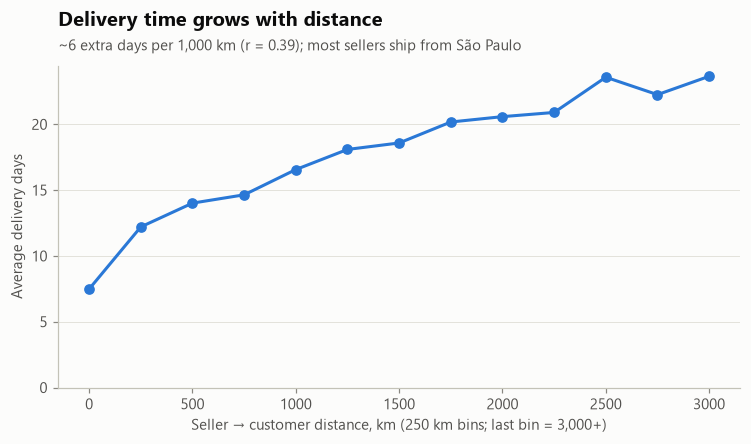

,route,orders,avg_days,late_pct,avg_freight,avg_review
0,Same state,34149,7.90,4.60,15.19,4.28
1,Cross-state,60782,15.20,8.20,26.55,4.11


In [ ]:
dist = query("""
    SELECT least(floor(max_distance_km / 250) * 250, 3000) AS distance_bin,
           count(*) AS orders, avg(delivery_days) AS avg_days, 100 * avg(is_late::INT) AS late_pct
    FROM marts.fact_orders
    WHERE is_delivered AND in_analysis_window AND max_distance_km IS NOT NULL
    GROUP BY 1 ORDER BY 1
""")
r = query("""SELECT corr(max_distance_km, delivery_days) FROM marts.fact_orders
               WHERE is_delivered AND in_analysis_window""").iloc[0, 0]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(dist["distance_bin"], dist["avg_days"], color=viz.BLUE, marker="o")
ax.set_xlabel("Seller → customer distance, km (250 km bins; last bin = 3,000+)")
ax.set_ylabel("Average delivery days")
ax.set_ylim(0)
ax.set_title("Delivery time grows with distance")
viz.subtitle(ax, f"~6 extra days per 1,000 km (r = {r:.2f}); most sellers ship from São Paulo")
viz.save(fig, "distance_vs_delivery")
plt.show()

query("""
    WITH single_seller AS (
        SELECT f.*, any_value(i.seller_id) AS seller_id
        FROM marts.fact_orders f JOIN marts.fact_order_items i USING (order_id)
        WHERE f.is_delivered AND f.in_analysis_window AND f.seller_count = 1
        GROUP BY ALL
    )
    SELECT CASE WHEN s.state = o.customer_state THEN 'Same state' ELSE 'Cross-state' END AS route,
           count(*) AS orders, round(avg(delivery_days), 1) AS avg_days,
           round(100 * avg(is_late::INT), 1) AS late_pct, round(avg(freight_value), 2) AS avg_freight,
           round(avg(review_score), 2) AS avg_review
    FROM single_seller o JOIN marts.dim_seller s USING (seller_id)
    GROUP BY 1
""")

In [ ]:
query("""
    SELECT 'sellers' AS side, state, round(100 * count(*) / sum(count(*)) OVER (), 1) AS share_pct
    FROM marts.dim_seller GROUP BY state QUALIFY row_number() OVER (ORDER BY count(*) DESC) <= 3
    UNION ALL
    SELECT 'orders', customer_state, round(100 * count(*) / sum(count(*)) OVER (), 1)
    FROM marts.fact_orders WHERE in_analysis_window GROUP BY customer_state
    QUALIFY row_number() OVER (ORDER BY count(*) DESC) <= 3
""")

,side,state,share_pct
0,sellers,SP,59.70
1,sellers,PR,11.30
2,sellers,MG,7.90
3,orders,SP,42.00
4,orders,RJ,12.90
5,orders,MG,11.70


## Findings

1. **Revenue is concentrated:** the top 10% of sellers generate ~66% of revenue, and the top 1% generate ~25%. Seller relationships are a key risk.
2. **164 high-volume sellers with poor quality hold 34% of revenue** (R$5.2M). Their late rate is nearly double that of the best sellers.
3. **Distance drives delay.** 60% of sellers are in São Paulo (vs 42% of orders), and every extra 1,000 km adds ~6 days.
   Same-state orders take **7.9 days with 4.6% late**; cross-state orders take **15.2 days with 8.2% late**, and freight is 75% higher.
4. The **North-East** pays twice: the highest late rates (14–21%) *and* the highest freight share.

## Recommendations

| Action | Why | Metric |
|---|---|---|
| Account-manage the top "fix first" sellers: dispatch SLA + carrier review | 34% of revenue at reputational risk | Seller late rate, negative-review % |
| Recruit sellers / open a fulfilment hub in the North-East | Cuts distance, delivery time, freight and lateness together | NE late rate, NE freight share |
| Rank search results by local stock / seller distance | Cheaper, faster, better-rated orders | Same-state order share |
| Monitor seller concentration (top-10% share) as a risk KPI | Losing a few sellers would hurt badly | Top-10% revenue share |